# Clasificación de textos médicos con TF-IDF y reducción de dimensionalidad

Clasificación de artículos biomédicos según el tipo de cáncer que tratan (pulmón, tiroides o colon). El texto se limpia con NLTK, se representa con TF-IDF y se reduce con descomposición en valores singulares (la versión de PCA para matrices dispersas); sobre esa representación se entrena una regresión logística con pesos de clase para el desbalance.

Datos: [Biomedical Text Publication Classification](https://www.kaggle.com/datasets/falgunipatel19/biomedical-text-publication-classification) (Kaggle), descargados con `kagglehub`.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

nltk.download('stopwords', quiet=True)
_ = nltk.download('wordnet', quiet=True)

## 1. Datos

In [2]:
ruta = kagglehub.dataset_download('falgunipatel19/biomedical-text-publication-classification')
df = pd.read_csv(f'{ruta}/alldata_1_for_kaggle.csv', encoding='MacRoman').iloc[:, 1:]
df.columns = ['clase', 'texto']
print('Registros:', len(df))
print('Duplicados exactos:', df.duplicated().sum())
print('Textos repetidos con distinta clase:', df['texto'].duplicated().sum() - df.duplicated().sum())

Registros: 7570


Duplicados exactos: 6574


Textos repetidos con distinta clase: 0


El 87 % de los registros son copias exactas de otros. Se eliminan antes de partir los datos: si no, el mismo artículo quedaría en entrenamiento y en prueba y la evaluación sería optimista.

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print('Artículos únicos:', len(df))
print(df['clase'].value_counts())
print(f"\nLongitud mediana: {df['texto'].str.len().median():,.0f} caracteres")

X_train, X_test, y_train, y_test = train_test_split(
    df['texto'], df['clase'], test_size=0.3, stratify=df['clase'], random_state=42)
print(f'\nEntrenamiento: {len(X_train)} | Prueba: {len(X_test)}')

Artículos únicos: 996
clase
Lung_Cancer       452
Thyroid_Cancer    283
Colon_Cancer      261
Name: count, dtype: int64

Longitud mediana: 26,339 caracteres

Entrenamiento: 697 | Prueba: 299


La partición es estratificada (70/30) para conservar la proporción de clases; la prueba no se toca hasta el final.

## 2. Limpieza del texto

Minúsculas, solo palabras alfabéticas de más de tres letras (se descartan números y fragmentos como «0000» o «gse8894»), sin palabras vacías del inglés y lematizadas.

In [4]:
vacias = set(stopwords.words('english'))
lematizador = WordNetLemmatizer()

def limpiar(texto):
    palabras = re.findall(r'[a-z]{4,}', texto.lower())
    return ' '.join(lematizador.lemmatize(p) for p in palabras if p not in vacias)

X_train_l = X_train.map(limpiar)
X_test_l = X_test.map(limpiar)
print(X_train_l.iloc[0][:400])

proband father sister unaffected peripheral blood sample obtained individual family member considered critical study excluded pedigree chart preserve confidentiality whole exome sequencing performed individual obtaining permission institutional review board okayama university hospital informed consent patient family member performed whole exome sequencing study tumor sample tumor peripheral blood 


## 3. TF-IDF y reducción de dimensionalidad

TF-IDF se ajusta solo con los textos de entrenamiento y descarta palabras que aparecen en menos de dos documentos. La matriz resultante tiene decenas de miles de columnas, casi todas en cero. En lugar de densificarla y estandarizarla para aplicar PCA (lo que destruye la dispersión y escala igual a las palabras raras que a las frecuentes), se usa `TruncatedSVD`, que trabaja directamente sobre la matriz dispersa.

Matriz TF-IDF: 697 documentos × 35,002 palabras (1.9% de celdas distintas de cero)


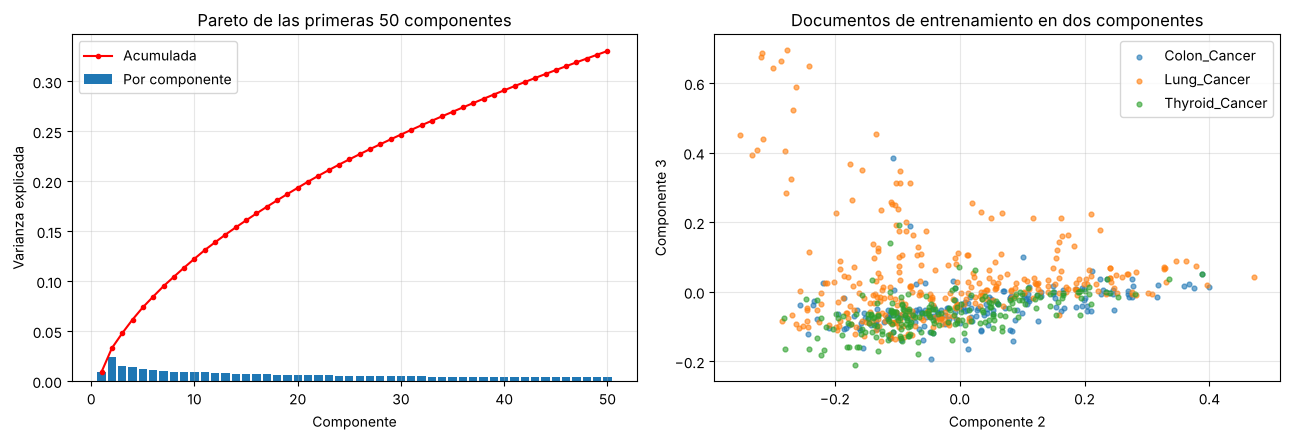

Varianza acumulada: 33.0% con 50 componentes, 79.2% con 300


In [5]:
tfidf = TfidfVectorizer(min_df=2)
T_train = tfidf.fit_transform(X_train_l)
vocab = tfidf.get_feature_names_out()
print(f'Matriz TF-IDF: {T_train.shape[0]} documentos × {T_train.shape[1]:,} palabras '
      f'({T_train.nnz / np.prod(T_train.shape):.1%} de celdas distintas de cero)')

svd = TruncatedSVD(n_components=300, random_state=42).fit(T_train)
acumulada = np.cumsum(svd.explained_variance_ratio_)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].bar(range(1, 51), svd.explained_variance_ratio_[:50], label='Por componente')
ejes[0].plot(range(1, 51), acumulada[:50], color='red', marker='.', label='Acumulada')
ejes[0].set_xlabel('Componente')
ejes[0].set_ylabel('Varianza explicada')
ejes[0].set_title('Pareto de las primeras 50 componentes')
ejes[0].legend()

Z = svd.transform(T_train)
for clase in sorted(y_train.unique()):
    m = (y_train == clase).to_numpy()
    ejes[1].scatter(Z[m, 1], Z[m, 2], s=12, alpha=0.6, label=clase)
ejes[1].set_xlabel('Componente 2')
ejes[1].set_ylabel('Componente 3')
ejes[1].set_title('Documentos de entrenamiento en dos componentes')
ejes[1].legend()
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(f'Varianza acumulada: {acumulada[49]:.1%} con 50 componentes, {acumulada[299]:.1%} con 300')

La primera componente de un SVD sin centrar recoge sobre todo el tamaño promedio de los documentos, por eso se grafican la segunda y la tercera. Las palabras con más peso en las primeras componentes muestran qué temas capturan:

In [6]:
for k in range(1, 4):
    principales = vocab[np.argsort(-np.abs(svd.components_[k]))[:12]]
    print(f'Componente {k + 1}:', ', '.join(principales))

Componente 2: cell, patient, expression, egfr, mutation, study, protein, mouse, cadherin, trial, covid, apoptosis
Componente 3: egfr, mutation, erlotinib, sanger, sequencing, covid, test, eurtac, tumor, exon, nsclc, risk
Componente 4: gene, patient, cancer, covid, lung, cell, mutation, genotype, smoking, smoker, polymorphism, risk


## 4. Clasificación

Regresión logística multinomial con `class_weight='balanced'` para compensar que hay más artículos de pulmón. El número de componentes se elige con validación cruzada sobre el entrenamiento, usando F1 macro (promedio entre clases, sensible al desbalance), y se compara con usar todo el vocabulario.

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)
logistica = LogisticRegression(class_weight='balanced', max_iter=2000)

candidatos = {f'SVD {k}': make_pipeline(TfidfVectorizer(min_df=2), TruncatedSVD(k, random_state=42), logistica)
              for k in (10, 50, 100, 300)}
candidatos['TF-IDF completo'] = make_pipeline(TfidfVectorizer(min_df=2), logistica)

resultados = {}
for nombre, modelo in candidatos.items():
    f1 = cross_val_score(modelo, X_train_l, y_train, cv=cv, scoring='f1_macro')
    resultados[nombre] = f1
    print(f'{nombre:>16}: F1 macro {f1.mean():.3f} ± {f1.std():.3f}')

          SVD 10: F1 macro 0.592 ± 0.041


          SVD 50: F1 macro 0.698 ± 0.043


         SVD 100: F1 macro 0.714 ± 0.040


         SVD 300: F1 macro 0.731 ± 0.047


 TF-IDF completo: F1 macro 0.724 ± 0.045


Modelo elegido por validación cruzada: SVD 300


                precision    recall  f1-score   support

  Colon_Cancer      0.512     0.538     0.525        78
   Lung_Cancer      0.963     0.956     0.959       136
Thyroid_Cancer      0.561     0.541     0.551        85

      accuracy                          0.729       299
     macro avg      0.679     0.679     0.678       299
  weighted avg      0.731     0.729     0.730       299



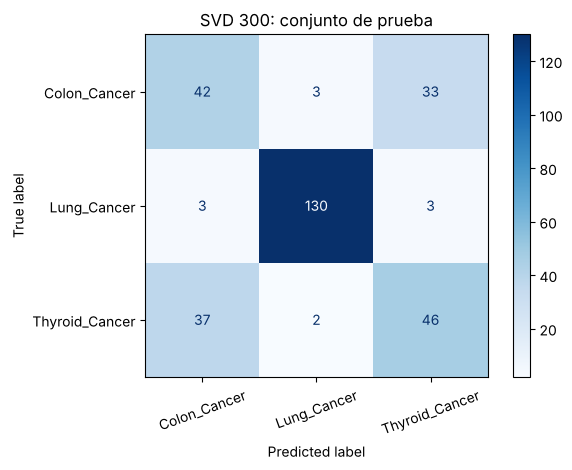

In [8]:
mejor = max(resultados, key=lambda n: resultados[n].mean())
print('Modelo elegido por validación cruzada:', mejor)
modelo = candidatos[mejor].fit(X_train_l, y_train)
pred = modelo.predict(X_test_l)
print(classification_report(y_test, pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues', xticks_rotation=20)
plt.title(f'{mejor}: conjunto de prueba')
plt.tight_layout()
plt.show()

## 5. Calidad de las etiquetas

La confusión entre colon y tiroides es mucho mayor que la esperable entre dos temas tan distintos. Contar qué órgano se menciona más en cada artículo muestra por qué:

In [9]:
organo = df['texto'].str.lower().apply(
    lambda s: max(['colo', 'lung', 'thyroid'], key=s.count)).map(
    {'colo': 'colon', 'lung': 'pulmón', 'thyroid': 'tiroides'})
display(pd.crosstab(df['clase'], organo, rownames=['Etiqueta'], colnames=['Órgano más mencionado']))

Órgano más mencionado,colon,pulmón,tiroides
Etiqueta,,,
Colon_Cancer,206,51,4
Lung_Cancer,93,359,0
Thyroid_Cancer,147,56,80


**Análisis**

- Eliminar duplicados cambia el problema: de 7.570 registros quedan 996 artículos, y la clase mayoritaria pasa a ser pulmón (452).
- La reducción con SVD conserva la información útil: con 300 componentes (79 % de la varianza) el F1 macro en validación cruzada (0,731) iguala al de usar las 35.000 palabras (0,724). Con 10 componentes cae a 0,59.
- En prueba, el modelo elegido obtiene 0,73 de exactitud y 0,68 de F1 macro. Pulmón se reconoce casi sin errores (F1 0,96); colon y tiroides se confunden entre sí (F1 alrededor de 0,53 y 0,55).
- La tabla de arriba explica esa confusión: 147 de los 283 artículos etiquetados como cáncer de tiroides mencionan más el colon que la tiroides, y solo 80 tienen a la tiroides como tema principal. Las etiquetas del dataset tienen ruido entre esas dos clases, y ningún modelo puede superar ese límite sin corregirlas. Con etiquetas así, la cifra de prueba mide tanto la calidad del dataset como la del modelo.